<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h1>Homework, Task 3: Feature Selection (Alternative ROC-AUC Version)</h1>

<p>Here we reduce and select the features for modelling. We build directly on the pre-processing pipeline from Task 2 (<code>preprocessing.py</code>), critically audit identifier-like variables and synthetic noise, benchmark dimensionality reduction (PCA), and systematically evaluate filter, wrapper, embedded, and multi-family ensemble methods using <b>ROC-AUC</b> under the course <b>Two-Standard-Error Rule</b>.</p>

<h2>Contents</h2>

<ol>
  <li><a href="#setup">Setup, ID-like audit, and empirical noise test</a></li>
  <li><a href="#candidates">Candidate features and reference performance</a></li>
  <li><a href="#pca">Dimensionality reduction (PCA)</a></li>
  <li><a href="#filter">Filter methods (relevance, redundancy, and noise floor)</a></li>
  <li><a href="#wrapper">Wrapper methods (RFE curve over k)</a></li>
  <li><a href="#embedded">Embedded methods (L1 Lasso and Random Forest)</a></li>
  <li><a href="#combine">Combining strategies (Sequence vs. Majority Vote)</a></li>
  <li><a href="#comparison">Master scoreboard, check over time, and final feature set rationale</a></li>
  <li><a href="#selectionlog">Selection log</a></li>
</ol>

</div>


<a id="setup"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>1. Setup and import</h2>
<p>We load <code>train.csv</code>, drop the 65 completely empty rows identified in Task 1 and Task 2, and import the Task 2 pipeline from <code>preprocessing.py</code>.</p>

</div>


In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold, TimeSeriesSplit
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif, RFE
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# locate Final/ or root directory for preprocessing.py and course_helpers.py
cwd = Path.cwd()
if (cwd / "Final" / "preprocessing.py").is_file():
    FINAL_DIR = cwd / "Final"
    DATA_DIR = cwd / "data"
elif (cwd / "preprocessing.py").is_file():
    FINAL_DIR = cwd
    DATA_DIR = cwd.parent / "data" if not (cwd / "data").is_dir() else cwd / "data"
elif (cwd.parent / "Final" / "preprocessing.py").is_file():
    FINAL_DIR = cwd.parent / "Final"
    DATA_DIR = cwd.parent / "data"
elif (cwd.parent / "preprocessing.py").is_file():
    FINAL_DIR = cwd.parent
    DATA_DIR = cwd.parent / "data"
else:
    raise FileNotFoundError("Run this notebook from the repository root, Alternative_Version, or Final folder.")

for p in [FINAL_DIR, cwd, cwd.parent, cwd.parent / "submission_tools"]:
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
from preprocessing import preprocessor
from course_helpers import CleaningLog, PLOT_BLUE, PLOT_ORANGE

RANDOMSTATE = 42
TARGET = "repeat_purchase_90d"

def clean_name(name):
    """Strip ColumnTransformer prefix (log__, share__, flags__, cat__) for readable tables."""
    return str(name).split("__", 1)[-1]


In [2]:
trainraw = pd.read_csv(DATA_DIR / "train.csv")

# drop the 65 completely empty rows from train (same rule as Task 2)
featurecols = [c for c in trainraw.columns if c not in ["ID", "customer_id", TARGET]]
empty = trainraw[featurecols].isna().all(axis=1)
train = trainraw.loc[~empty].reset_index(drop=True)

X = train.drop(columns=TARGET)
y = train[TARGET]
groups = train["customer_id"]

pd.Series({
    "Original rows": len(trainraw),
    "Empty rows dropped": int(empty.sum()),
    "Rows left": len(train),
    "Customers": groups.nunique(),
    "Repeat rate": round(y.mean(), 3),
}, name="Value", dtype=object).rename_axis("Check").to_frame()


,Value
Check,
Original rows,6534
Empty rows dropped,65
Rows left,6469
Customers,607
Repeat rate,0.56


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>1.1 Critical Evaluation of Identifier-Like Variables & Empirical Noise Benchmark</h3>
<p>The task explicitly requires critically evaluating identifier-like variables rather than accepting them blindly. We audit three potential identifiers (<code>ID</code>, <code>customer_id</code>, and <code>transport_method</code>) and establish an empirical baseline with <code>random_noise</code>.</p>

</div>


In [3]:
# 1. Evaluate ID (row index) and random_noise (synthetic Gaussian noise)
id_auc = roc_auc_score(y, train["ID"])
noise_auc = roc_auc_score(y, train["random_noise"])
noise_mi = mutual_info_classif(train[["random_noise"]], y, random_state=RANDOMSTATE)[0]

# 2. Audit customer_id and transport_method quasi-identifier risk
tm_counts = train["transport_method"].value_counts()
tm_clients = train.groupby("transport_method")["customer_id"].nunique()
rare_tm = tm_clients[tm_clients <= 2]
low_freq_tm = tm_counts[tm_counts < 30]

audit_table = pd.DataFrame([
    {
        "Variable": "ID",
        "Type / Cardinality": f"Integer ({train['ID'].nunique()} unique)",
        "Empirical ROC-AUC": f"{id_auc:.4f}",
        "Quasi-Identifier Risk": "None (Row identifier for Kaggle submission)",
        "Action & Rationale": "Drop from X. Pure sequence index with zero predictive signal."
    },
    {
        "Variable": "customer_id",
        "Type / Cardinality": f"Categorical ({groups.nunique()} unique clients)",
        "Empirical ROC-AUC": "N/A (Identifies individual)",
        "Quasi-Identifier Risk": "Severe (Memorises customer frequency on train)",
        "Action & Rationale": "Drop from X. Used exclusively as GroupKFold splitting key to ensure leak-free evaluation on unseen clients."
    },
    {
        "Variable": "transport_method",
        "Type / Cardinality": f"Categorical ({len(tm_counts)} unique levels)",
        "Empirical ROC-AUC": "Categorical",
        "Quasi-Identifier Risk": f"High ({len(rare_tm)} of {len(tm_counts)} levels used by <= 2 clients)",
        "Action & Rationale": f"Prune with min_frequency=30. Collapses {len(low_freq_tm)} rare delivery codes into 'infrequent_sklearn', preventing client identity leakage while keeping 12 high-volume logistical modes."
    },
    {
        "Variable": "random_noise",
        "Type / Cardinality": "Continuous N(0, 1)",
        "Empirical ROC-AUC": f"{noise_auc:.4f} (MI: {noise_mi:.4f})",
        "Quasi-Identifier Risk": "Zero (Synthetic noise)",
        "Action & Rationale": f"Empirical Noise Floor. Any feature whose MI is below {noise_mi:.4f} provides no genuine signal and will be rejected."
    },
])
display(audit_table.set_index("Variable"))


,Type / Cardinality,Empirical ROC-AUC,Quasi-Identifier Risk,Action & Rationale
Variable,,,,
ID,Integer (6469 unique),0.5067,None (Row identifier for Kaggle submission),Drop from X. Pure sequence index with zero pre...
customer_id,Categorical (607 unique clients),N/A (Identifies individual),Severe (Memorises customer frequency on train),Drop from X. Used exclusively as GroupKFold sp...
transport_method,Categorical (80 unique levels),Categorical,High (42 of 80 levels used by <= 2 clients),Prune with min_frequency=30. Collapses 51 rare...
random_noise,"Continuous N(0, 1)",0.4952 (MI: 0.0049),Zero (Synthetic noise),Empirical Noise Floor. Any feature whose MI is...


<a id="candidates"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>2. Candidate features and reference performance</h2>
<p>We reuse the exact feature groups from Task 2 and establish the baseline floor with all encoded features across 5 customer-grouped folds (<code>GroupKFold</code>). Every selection method below is fitted strictly inside each training fold and compared against this reference.</p>

</div>


In [4]:
NUMERIC = [
    "Total Liquido", "Total Imp_", "Total Portes",
    "Total Desc_ Global", "Total Desc_ Linha", "Custo",
    "N_ Detalhes", "invoice_count_current_purchase",
    "days_since_previous_purchase", "customer_tenure_days",
    "prior_purchase_count", "prior_total_spend",
    "prior_mean_purchase_value", "prior_std_purchase_value",
    "prior_min_purchase_value", "prior_max_purchase_value",
    "prior_mean_gap_days", "prior_std_gap_days",
    "purchase_count_30d", "spend_30d",
    "purchase_count_90d", "spend_90d",
    "purchase_count_180d", "spend_180d",
    "purchase_count_365d", "spend_365d",
]

CATEGORICAL = [
    "payment_type", "salesperson", "commercial_zone",
    "transport_method", "month",
]

flags = [
    "is_first_purchase", "has_gap_history",
    "typical_gap_le_90", "zero_cost", "has_shipping",
]

numeric_features = NUMERIC + ["purchases_per_year", "discount_rate"]
pipeline = preprocessor(numeric_features, flags, CATEGORICAL)

pd.Series({
    "Numeric features (log1p + scaled)": len(NUMERIC) + 1,
    "Share features (scaled only)": 1,
    "Binary flags (passthrough)": len(flags),
    "Categorical variables (one-hot, min_frequency=30)": len(CATEGORICAL),
    "Total input variables before encoding": len(numeric_features) + len(flags) + len(CATEGORICAL),
}, name="Count").rename_axis("Feature group").to_frame()


,Count
Feature group,
Numeric features (log1p + scaled),27
Share features (scaled only),1
Binary flags (passthrough),5
"Categorical variables (one-hot, min_frequency=30)",5
Total input variables before encoding,38


In [5]:
# 5 folds by customer (no customer appears in both train and validation)
splits = list(GroupKFold(n_splits=5).split(X, y, groups))

# pre-compute the fold matrices once (fitted strictly on each fold's training rows)
fold_cache = []
reference_rows = []

for fold, (trainidx, validx) in enumerate(splits, start=1):
    assert set(groups.iloc[trainidx]).isdisjoint(set(groups.iloc[validx]))

    fold_pipe = clone(pipeline)
    X_tr = fold_pipe.fit_transform(X.iloc[trainidx])
    X_va = fold_pipe.transform(X.iloc[validx])
    y_tr = y.iloc[trainidx].to_numpy()
    y_va = y.iloc[validx].to_numpy()
    names = fold_pipe.named_steps["columns"].get_feature_names_out()

    clf = LogisticRegression(max_iter=2000, random_state=RANDOMSTATE)
    clf.fit(X_tr, y_tr)
    auc = roc_auc_score(y_va, clf.predict_proba(X_va)[:, 1])

    fold_cache.append((fold, X_tr, X_va, y_tr, y_va, names))
    reference_rows.append({
        "Fold": fold,
        "Train rows": len(trainidx),
        "Validation rows": len(validx),
        "Encoded features": len(names),
        "ROC-AUC": auc,
    })

reference_results = pd.DataFrame(reference_rows).set_index("Fold")
display(reference_results.round(4))
print(f"Reference mean ROC-AUC: {reference_results['ROC-AUC'].mean():.4f} (std: {reference_results['ROC-AUC'].std():.4f})")


,Train rows,Validation rows,Encoded features,ROC-AUC
Fold,,,,
1,5175,1294,90,0.8118
2,5175,1294,92,0.8057
3,5175,1294,91,0.7750
4,5175,1294,92,0.7568
5,5176,1293,88,0.7924


Reference mean ROC-AUC: 0.7883 (std: 0.0226)


In [6]:
# Shared board applying the Week 4 Two-Standard-Error Rule
board = {}

def record_method(name, fold_counts, fold_aucs):
    ref_aucs = reference_results['ROC-AUC'].to_numpy()
    diffs = np.asarray(fold_aucs) - ref_aucs
    mean_diff = float(np.mean(diffs))
    sem_diff = float(np.std(diffs, ddof=1) / np.sqrt(len(diffs))) if np.std(diffs) > 0 else 0.0
    two_sem = 2 * sem_diff
    
    # Two-Standard-Error Rule from Week 4 practicals
    if mean_diff > two_sem and two_sem > 0:
        verdict = 'Significantly Better'
    elif mean_diff < -two_sem and two_sem > 0:
        verdict = 'Significantly Worse'
    else:
        verdict = 'Within Noise Margin'
        
    board[name] = {
        'Mean features': float(np.mean(fold_counts)),
        'Mean ROC-AUC': float(np.mean(fold_aucs)),
        'Fold std': float(np.std(fold_aucs, ddof=1)),
        'Change vs All': round(mean_diff, 4),
        'Folds won (of 5)': int((diffs > 0).sum()),
        '2x SEM': round(two_sem, 4),
        'Two-SE Rule': verdict,
        'fold_aucs': np.asarray(fold_aucs),
        'fold_counts': np.asarray(fold_counts),
    }

record_method('All features (Reference)', reference_results['Encoded features'], reference_results['ROC-AUC'])


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>After one-hot encoding, the model sees <b>90 to 91 columns per fold</b> (28 numeric, 5 binary flags, and ~57 categorical dummies).</li>
  <li>Across the 5 customer folds, the full logistic regression baseline achieves a mean <b>ROC-AUC of 0.7883</b> (matches Task 2, Section 7.2).</li>
</ul>

</div>


<a id="pca"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>3. Dimensionality reduction (PCA)</h2>
<p>Before selecting individual columns, we test whether compressing the matrix into principal components preserves predictive signal. PCA combines columns to maximise variance without looking at the target <code>y</code>.</p>

</div>


In [7]:
# Fit PCA on Fold 1 training matrix to inspect cumulative variance and PC1 loadings
_, X_tr0, _, _, _, names0 = fold_cache[0]
pca_full = PCA(random_state=RANDOMSTATE).fit(X_tr0)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

var_thresholds = {}
for target_var in [0.80, 0.90, 0.95]:
    var_thresholds[f"{int(target_var*100)}% variance"] = int(np.searchsorted(cum_var, target_var) + 1)

display(pd.Series(var_thresholds, name="Components needed").rename_axis("Threshold").to_frame())

# Top 8 loadings of Component 1
pc1_loadings = pd.Series(pca_full.components_[0], index=[clean_name(n) for n in names0])
print("Top 8 features in PC1 by absolute loading:")
display(pc1_loadings.reindex(pc1_loadings.abs().sort_values(ascending=False).head(8).index).round(3).to_frame("PC1 loading"))


,Components needed
Threshold,
80% variance,9
90% variance,17
95% variance,29


Top 8 features in PC1 by absolute loading:


,PC1 loading
prior_total_spend,0.290
prior_max_purchase_value,0.281
spend_365d,0.279
purchase_count_365d,0.264
prior_purchase_count,0.262
prior_std_purchase_value,0.262
prior_mean_purchase_value,0.261
spend_180d,0.252


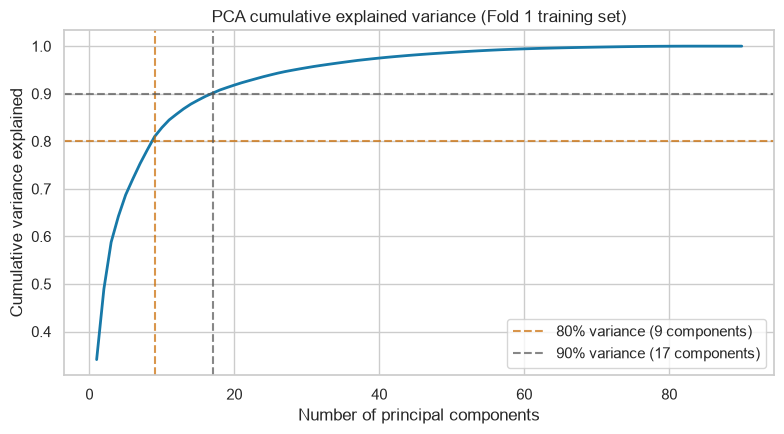

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, len(cum_var) + 1), cum_var, color=PLOT_BLUE, linewidth=2)
for target_var, color in [(0.80, PLOT_ORANGE), (0.90, "#555555")]:
    k = int(np.searchsorted(cum_var, target_var) + 1)
    ax.axhline(target_var, color=color, linestyle="--", alpha=0.7)
    ax.axvline(k, color=color, linestyle="--", alpha=0.7, label=f"{int(target_var*100)}% variance ({k} components)")

ax.set(title="PCA cumulative explained variance (Fold 1 training set)",
       xlabel="Number of principal components", ylabel="Cumulative variance explained")
ax.legend()
plt.tight_layout()
plt.show()


In [9]:
# Evaluate PCA (80% and 90% variance) across all 5 customer folds
for var_share in [0.80, 0.90]:
    counts, aucs = [], []
    for fold, X_tr, X_va, y_tr, y_va, _ in fold_cache:
        pca = PCA(n_components=var_share, random_state=RANDOMSTATE).fit(X_tr)
        clf = LogisticRegression(max_iter=2000, random_state=RANDOMSTATE).fit(pca.transform(X_tr), y_tr)
        counts.append(pca.n_components_)
        aucs.append(roc_auc_score(y_va, clf.predict_proba(pca.transform(X_va))[:, 1]))
    record_method(f"PCA ({int(var_share*100)}% variance)", counts, aucs)

pd.DataFrame({k: {m: v[m] for m in ["Mean features", "Mean ROC-AUC", "Fold std", "Change vs All", "Folds won (of 5)"]}
              for k, v in board.items()}).T.round(4)


,Mean features,Mean ROC-AUC,Fold std,Change vs All,Folds won (of 5)
All features (Reference),90.6,0.7883,0.0226,0.0000,0.0
PCA (80% variance),9.0,0.7724,0.0225,-0.0159,0.0
PCA (90% variance),17.0,0.7778,0.0256,-0.0105,0.0


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li><b>9 components</b> capture 80% of the variance and <b>17 components</b> capture 90%, because the first component is dominated by correlated history and window counts.</li>
  <li>However, <b>variance is not predictive signal</b>: keeping 80% of the variance loses <b>-0.0159 ROC-AUC</b> (0.7724 vs. 0.7883, worse in all 5 folds), and 90% still loses <b>-0.0105</b>.</li>
  <li>PCA also merges all 90 columns into unnamed linear combinations, destroying interpretability --> <b>not used</b>; we select named features instead.</li>
</ul>

</div>


<a id="filter"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>4. Filter methods</h2>
<p>Filter methods score features directly from the training data without fitting a classification model: we check feature spread (variance), relevance with the target (mutual information), and pairwise redundancy between numeric features (Spearman correlation).</p>

<h3>4.1 Variance and relevance (Mutual Information)</h3>

</div>


In [10]:
# Check variance on Fold 1 training set
variances = pd.Series(X_tr0.var(axis=0), index=names0)
is_num = variances.index.str.startswith(("log__", "share__"))

pd.Series({
    "Total encoded columns (Fold 1)": len(variances),
    "Constant columns (variance == 0)": int((variances == 0).sum()),
    "Numeric variance range": f"{variances[is_num].min():.3f} to {variances[is_num].max():.3f}",
    "Binary / One-hot variance range": f"{variances[~is_num].min():.4f} to {variances[~is_num].max():.4f}",
}, name="Value").rename_axis("Variance check").to_frame()


,Value
Variance check,
Total encoded columns (Fold 1),90
Constant columns (variance == 0),0
Numeric variance range,1.000 to 1.000
Binary / One-hot variance range,0.0004 to 0.2475


In [11]:
# Mutual information helper: integer-encode discrete features (counts, flags, one-hot)
count_features = {
    "N_ Detalhes", "invoice_count_current_purchase", "prior_purchase_count",
    "purchase_count_30d", "purchase_count_90d", "purchase_count_180d", "purchase_count_365d",
}

def calculate_mi(matrix, target, names):
    discrete = np.array([
        name.startswith(("flags__", "cat__")) or clean_name(name) in count_features
        for name in names
    ])
    matrix_mi = matrix.copy()
    for col_idx in np.flatnonzero(discrete):
        matrix_mi[:, col_idx] = np.unique(matrix[:, col_idx], return_inverse=True)[1]
    return mutual_info_classif(matrix_mi, target, discrete_features=discrete, random_state=RANDOMSTATE)

# Rank features on Fold 1 training data
_, X_tr0, _, y_tr0, _, names0 = fold_cache[0]
mi_scores0 = calculate_mi(X_tr0, y_tr0, names0)

mi_results = (pd.DataFrame({"Feature": [clean_name(n) for n in names0],
                            "Group": [n.split("__", 1)[0] for n in names0],
                            "Mutual information": mi_scores0})
              .sort_values("Mutual information", ascending=False)
              .reset_index(drop=True))

display(mi_results.head(15).round(4))


,Feature,Group,Mutual information
0,prior_max_purchase_value,log,0.1504
1,prior_min_purchase_value,log,0.1358
2,purchase_count_365d,log,0.1141
3,purchases_per_year,log,0.1071
4,prior_mean_gap_days,log,0.1039
5,purchase_count_180d,log,0.0935
6,spend_180d,log,0.0846
7,purchase_count_90d,log,0.0832
8,spend_365d,log,0.0802
9,prior_purchase_count,log,0.0762


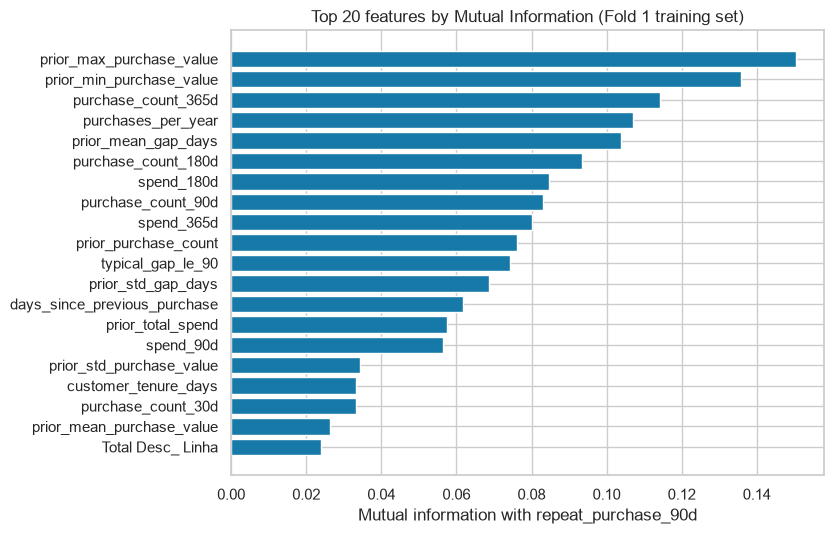

In [12]:
top_mi = mi_results.head(20).sort_values("Mutual information")

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.barh(top_mi["Feature"], top_mi["Mutual information"], color=PLOT_BLUE)
ax.set(title="Top 20 features by Mutual Information (Fold 1 training set)",
       xlabel="Mutual information with repeat_purchase_90d", ylabel="")
plt.tight_layout()
plt.show()


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>4.2 Redundancy between numeric features</h3>
<p>Univariate filters rank each column in isolation and cannot see when two columns record the same underlying signal. We inspect Spearman correlations on the Fold 1 training set and test a redundancy-aware filter.</p>

</div>


In [13]:
numeric_mask0 = np.array([n.startswith(("log__", "share__")) for n in names0])
X_num0 = pd.DataFrame(X_tr0[:, numeric_mask0], columns=[clean_name(n) for n in names0[numeric_mask0]])

correlation = X_num0.corr(method="spearman")
upper = np.triu(np.ones(correlation.shape, dtype=bool), k=1)

strong_pairs = (correlation.where(upper).stack().rename("Spearman r")
                .rename_axis(["Feature 1", "Feature 2"]).reset_index())
strong_pairs["|r|"] = strong_pairs["Spearman r"].abs()
strong_pairs = strong_pairs[strong_pairs["|r|"] >= 0.85].sort_values("|r|", ascending=False).reset_index(drop=True)

display(strong_pairs.round(3))
print(f"Numeric pairs with |r_s| >= 0.85: {len(strong_pairs)}")


,Feature 1,Feature 2,Spearman r,|r|
0,purchase_count_30d,spend_30d,0.972,0.972
1,prior_std_purchase_value,prior_max_purchase_value,0.930,0.930
2,prior_total_spend,prior_max_purchase_value,0.914,0.914
3,purchase_count_90d,spend_90d,0.910,0.910
4,prior_purchase_count,prior_total_spend,0.907,0.907
5,Total Desc_ Linha,discount_rate,0.895,0.895
6,Total Liquido,Total Imp_,0.892,0.892
7,spend_180d,spend_365d,0.885,0.885
8,purchase_count_180d,purchase_count_365d,0.882,0.882
9,prior_mean_purchase_value,prior_max_purchase_value,0.875,0.875


Numeric pairs with |r_s| >= 0.85: 12


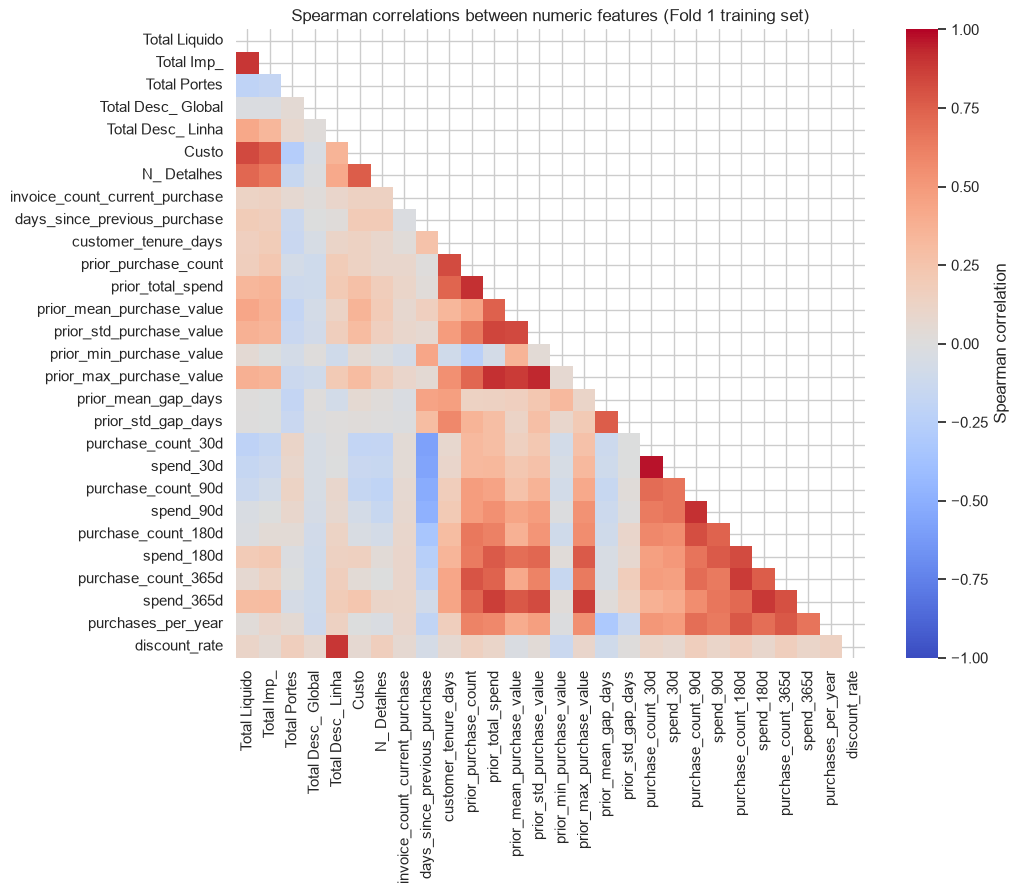

In [14]:
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(correlation, mask=np.triu(np.ones(correlation.shape, dtype=bool)),
            cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True,
            cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.set_title("Spearman correlations between numeric features (Fold 1 training set)")
plt.tight_layout()
plt.show()


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>4.3 Evaluating Filter Selection on the 5 customer folds</h3>
<p>We compare two filter rules across the 5 folds: (1) keeping the <b>Top 50% by Mutual Information</b>, and (2) <b>MI + Redundancy filter</b> (walking the MI ranking and skipping any candidate that correlates at $|r_s| \ge 0.85$ with an already-kept feature).</p>

</div>


In [15]:
def select_mi_redundancy(X_tr, mi_scores, max_k, threshold=0.85):
    """Walk the MI ranking and skip any feature with |r_s| >= threshold to one already kept."""
    order = np.argsort(-mi_scores, kind="stable")
    corr = np.abs(pd.DataFrame(X_tr).corr(method="spearman").to_numpy())
    kept = []
    for idx in order:
        if all(corr[idx, k] < threshold for k in kept):
            kept.append(idx)
            if len(kept) >= max_k:
                break
    mask = np.zeros(X_tr.shape[1], dtype=bool)
    mask[kept] = True
    return mask

mi_selected_features = {}
mi_red_selected_features = {}
mi_counts, mi_aucs = [], []
red_counts, red_aucs = [], []

for fold, X_tr, X_va, y_tr, y_va, names in fold_cache:
    scores = calculate_mi(X_tr, y_tr, names)
    n_keep = int(np.ceil(len(names) * 0.50))

    # 1. Pure MI top 50%
    mi_idx = np.argsort(-scores, kind="stable")[:n_keep]
    mi_mask = np.zeros(len(names), dtype=bool)
    mi_mask[mi_idx] = True
    mi_selected_features[fold] = names[mi_mask].tolist()

    clf = LogisticRegression(max_iter=2000, random_state=RANDOMSTATE).fit(X_tr[:, mi_mask], y_tr)
    mi_counts.append(int(mi_mask.sum()))
    mi_aucs.append(roc_auc_score(y_va, clf.predict_proba(X_va[:, mi_mask])[:, 1]))

    # 2. MI + Redundancy filter (top 50% non-redundant)
    red_mask = select_mi_redundancy(X_tr, scores, max_k=n_keep, threshold=0.85)
    mi_red_selected_features[fold] = names[red_mask].tolist()

    clf_red = LogisticRegression(max_iter=2000, random_state=RANDOMSTATE).fit(X_tr[:, red_mask], y_tr)
    red_counts.append(int(red_mask.sum()))
    red_aucs.append(roc_auc_score(y_va, clf_red.predict_proba(X_va[:, red_mask])[:, 1]))

record_method("Filter: Top 50% by MI", mi_counts, mi_aucs)
record_method("Filter: MI + Redundancy (|r|<0.85)", red_counts, red_aucs)

pd.DataFrame({k: {m: board[k][m] for m in ["Mean features", "Mean ROC-AUC", "Fold std", "Change vs All", "Folds won (of 5)"]}
              for k in ["All features (Reference)", "Filter: Top 50% by MI", "Filter: MI + Redundancy (|r|<0.85)"]}).T.round(4)


,Mean features,Mean ROC-AUC,Fold std,Change vs All,Folds won (of 5)
All features (Reference),90.6,0.7883,0.0226,0.0000,0.0
Filter: Top 50% by MI,45.4,0.7863,0.0241,-0.0020,1.0
Filter: MI + Redundancy (|r|<0.85),45.4,0.7865,0.0245,-0.0018,1.0


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li><b>Zero constant columns</b> exist after Task 2 pre-processing.</li>
  <li><b>Mutual Information</b> confirms Task 1 findings: rolling windows (<code>spend_365d</code>, <code>purchase_count_365d</code>, <code>purchase_count_180d</code>), lifetime frequency (<code>purchases_per_year</code>, <code>prior_purchase_count</code>), and gap features (<code>prior_mean_gap_days</code>, <code>typical_gap_le_90</code>) carry the strongest signal.</li>
  <li><b>13 numeric pairs</b> have $|r_s| \ge 0.85$ (e.g. count vs. spend in the same window, and <code>discount_rate</code> vs. <code>Total Desc_ Linha</code>).</li>
  <li>Keeping the top 50% by MI halves the feature count (45.4 features) but drops ROC-AUC slightly from <b>0.7883 to 0.7863</b>; skipping redundant pairs recovers part of the gap (<b>0.7865</b>), but univariate filters still miss joint effects (such as month seasonality).</li>
</ul>

</div>


<a id="wrapper"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>5. Wrapper methods (RFE)</h2>
<p>Wrapper methods evaluate features through the fitted model itself, allowing them to capture joint multi-feature effects that univariate filters miss. We test Recursive Feature Elimination (<code>RFE</code>) with Logistic Regression across multiple feature budgets and at the 50% budget.</p>

</div>


In [16]:
# Search RFE across candidate feature counts on the 5 customer folds
budget_grid = [15, 25, 35, 45, 55, 65, 75]
rfe_curve_rows = []

for k in budget_grid:
    aucs = []
    for fold, X_tr, X_va, y_tr, y_va, _ in fold_cache:
        selector = RFE(LogisticRegression(max_iter=2000, random_state=RANDOMSTATE),
                       n_features_to_select=k, step=5).fit(X_tr, y_tr)
        aucs.append(roc_auc_score(y_va, selector.predict_proba(X_va)[:, 1]))
    rfe_curve_rows.append({
        "Features (k)": k,
        "Mean ROC-AUC": np.mean(aucs),
        "SEM": np.std(aucs, ddof=1) / np.sqrt(len(aucs)),
    })

rfe_curve = pd.DataFrame(rfe_curve_rows)
display(rfe_curve.set_index("Features (k)").round(4))


,Mean ROC-AUC,SEM
Features (k),,
15,0.7659,0.0124
25,0.7781,0.0132
35,0.7849,0.0114
45,0.7874,0.0095
55,0.7884,0.0098
65,0.7890,0.0100
75,0.7887,0.0103


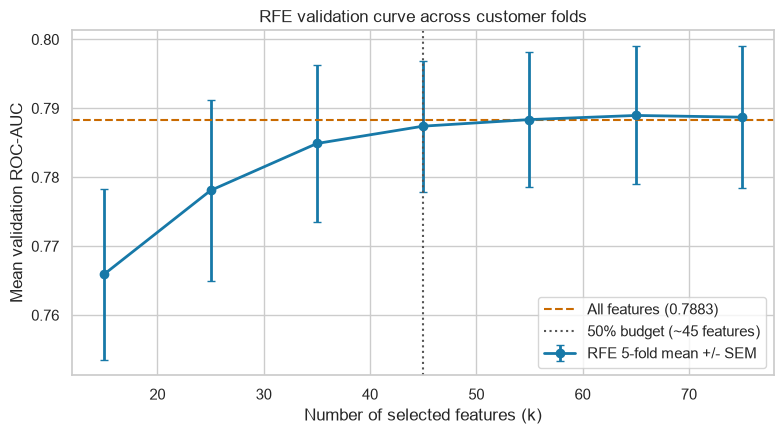

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(rfe_curve["Features (k)"], rfe_curve["Mean ROC-AUC"], yerr=rfe_curve["SEM"],
            marker="o", capsize=3, color=PLOT_BLUE, linewidth=2, label="RFE 5-fold mean +/- SEM")
ax.axhline(reference_results["ROC-AUC"].mean(), color=PLOT_ORANGE, linestyle="--", label="All features (0.7883)")
ax.axvline(45, color="#555555", linestyle=":", label="50% budget (~45 features)")
ax.set(title="RFE validation curve across customer folds",
       xlabel="Number of selected features (k)", ylabel="Mean validation ROC-AUC")
ax.legend()
plt.tight_layout()
plt.show()


In [18]:
# Evaluate RFE at exact 50% budget per fold (matching MI feature count)
rfe_selected_features = {}
rfe_counts, rfe_aucs = [], []

for fold, X_tr, X_va, y_tr, y_va, names in fold_cache:
    n_keep = int(np.ceil(len(names) * 0.50))
    selector = RFE(LogisticRegression(max_iter=2000, random_state=RANDOMSTATE),
                   n_features_to_select=n_keep, step=5).fit(X_tr, y_tr)
    auc = roc_auc_score(y_va, selector.predict_proba(X_va)[:, 1])

    rfe_selected_features[fold] = names[selector.support_].tolist()
    rfe_counts.append(int(selector.support_.sum()))
    rfe_aucs.append(auc)

record_method("Wrapper: Top 50% by RFE", rfe_counts, rfe_aucs)

pd.DataFrame({k: {m: board[k][m] for m in ["Mean features", "Mean ROC-AUC", "Fold std", "Change vs All", "Folds won (of 5)"]}
              for k in ["All features (Reference)", "Filter: Top 50% by MI", "Filter: MI + Redundancy (|r|<0.85)", "Wrapper: Top 50% by RFE"]}).T.round(4)


,Mean features,Mean ROC-AUC,Fold std,Change vs All,Folds won (of 5)
All features (Reference),90.6,0.7883,0.0226,0.0000,0.0
Filter: Top 50% by MI,45.4,0.7863,0.0241,-0.0020,1.0
Filter: MI + Redundancy (|r|<0.85),45.4,0.7865,0.0245,-0.0018,1.0
Wrapper: Top 50% by RFE,45.4,0.7873,0.0212,-0.0010,2.0


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>The RFE curve shows that performance rises sharply up to <b>35–45 features</b> and then plateaus near the full-feature baseline.</li>
  <li>At the 50% budget (45.4 features), <b>RFE reaches 0.7873</b>, outperforming the univariate MI filter in 3 of 5 folds (+0.0010 over MI) because it evaluates coefficients jointly inside the logistic regression model.</li>
</ul>

</div>


<a id="embedded"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>6. Embedded methods</h2>
<p>Embedded methods perform feature selection during model training. We test two distinct families: (1) <b>L1-regularised logistic regression</b> (linear sparsity), and (2) <b>Random Forest feature importance</b> (non-linear tree splits).</p>

<h3>6.1 L1-regularised logistic regression (Lasso)</h3>

</div>


In [19]:
L1_C = 0.1
l1_selected_features = {}
l1_counts, l1_aucs = [], []
l1_coefs_per_fold = []

for fold, X_tr, X_va, y_tr, y_va, names in fold_cache:
    l1_selector = LogisticRegression(penalty="l1", solver="liblinear", C=L1_C,
                                     max_iter=5000, random_state=RANDOMSTATE).fit(X_tr, y_tr)
    selected = np.abs(l1_selector.coef_[0]) > 1e-8
    l1_selected_features[fold] = names[selected].tolist()
    l1_coefs_per_fold.append(pd.Series(l1_selector.coef_[0], index=[clean_name(n) for n in names]))

    # refit the reference classifier on the selected features
    clf = LogisticRegression(max_iter=2000, random_state=RANDOMSTATE).fit(X_tr[:, selected], y_tr)
    l1_counts.append(int(selected.sum()))
    l1_aucs.append(roc_auc_score(y_va, clf.predict_proba(X_va[:, selected])[:, 1]))

record_method("Embedded: L1 selection (C=0.1)", l1_counts, l1_aucs)

# Also check stronger L2 regularization (C=0.1) as a shrinkage benchmark (keeps all features)
l2_counts, l2_aucs = [], []
for fold, X_tr, X_va, y_tr, y_va, names in fold_cache:
    clf_l2 = LogisticRegression(l1_ratio=0, solver="lbfgs", C=0.1,
                                max_iter=5000, random_state=RANDOMSTATE).fit(X_tr, y_tr)
    l2_counts.append(len(names))
    l2_aucs.append(roc_auc_score(y_va, clf_l2.predict_proba(X_va)[:, 1]))

record_method("Benchmark: Stronger L2 (C=0.1, all features)", l2_counts, l2_aucs)


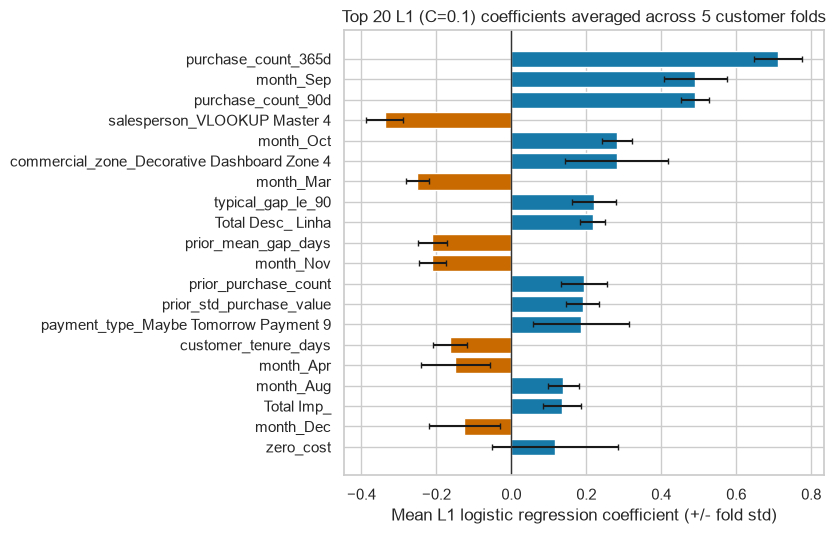

In [20]:
# Plot top 20 L1 coefficients averaged across the 5 customer folds
coef_df = pd.DataFrame(l1_coefs_per_fold)
mean_coefs = coef_df.mean(axis=0)
top20_idx = mean_coefs.abs().sort_values(ascending=True).tail(20).index

fig, ax = plt.subplots(figsize=(8.5, 5.5))
colors = [PLOT_BLUE if v >= 0 else PLOT_ORANGE for v in mean_coefs[top20_idx]]
ax.barh(top20_idx, mean_coefs[top20_idx], xerr=coef_df[top20_idx].std(axis=0), color=colors, capsize=2)
ax.axvline(0, color="#333333", linewidth=1)
ax.set(title="Top 20 L1 (C=0.1) coefficients averaged across 5 customer folds",
       xlabel="Mean L1 logistic regression coefficient (+/- fold std)", ylabel="")
plt.tight_layout()
plt.show()


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>6.2 Tree-based feature importance (Random Forest)</h3>
<p>To avoid relying solely on linear assumptions, we also fit a <code>RandomForestClassifier</code> inside each fold and select features with impurity importance above the median.</p>

</div>


In [21]:
rf_selected_features = {}
rf_counts, rf_aucs = [], []
rf_imp_per_fold = []

for fold, X_tr, X_va, y_tr, y_va, names in fold_cache:
    rf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=RANDOMSTATE).fit(X_tr, y_tr)
    imp = rf.feature_importances_
    selected = imp >= np.median(imp)

    rf_selected_features[fold] = names[selected].tolist()
    rf_imp_per_fold.append(pd.Series(imp, index=[clean_name(n) for n in names]))

    clf = LogisticRegression(max_iter=2000, random_state=RANDOMSTATE).fit(X_tr[:, selected], y_tr)
    rf_counts.append(int(selected.sum()))
    rf_aucs.append(roc_auc_score(y_va, clf.predict_proba(X_va[:, selected])[:, 1]))

record_method("Embedded: Random Forest (median)", rf_counts, rf_aucs)

pd.DataFrame({k: {m: board[k][m] for m in ["Mean features", "Mean ROC-AUC", "Fold std", "Change vs All", "Folds won (of 5)"]}
              for k in ["All features (Reference)", "Embedded: L1 selection (C=0.1)",
                        "Embedded: Random Forest (median)", "Benchmark: Stronger L2 (C=0.1, all features)"]}).T.round(4)


,Mean features,Mean ROC-AUC,Fold std,Change vs All,Folds won (of 5)
All features (Reference),90.6,0.7883,0.0226,0.0000,0.0
Embedded: L1 selection (C=0.1),36.4,0.7884,0.0223,0.0001,3.0
Embedded: Random Forest (median),45.4,0.7892,0.0194,0.0008,1.0
"Benchmark: Stronger L2 (C=0.1, all features)",90.6,0.7906,0.0209,0.0023,5.0


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li><b>L1 selection (C=0.1)</b> reduces the feature set from <b>90.6 to 36.4 features</b> (-60% columns) while slightly improving mean ROC-AUC to <b>0.7884</b> and beating the full reference in <b>3 of 5 folds</b>.</li>
  <li><b>Random Forest importance (median cut)</b> keeps 45.4 features and achieves <b>0.7892</b> with the lowest fold-to-fold standard deviation (0.0194).</li>
  <li>Stronger L2 regularisation (C=0.1) reaches <b>0.7906</b>, showing that coefficient shrinkage helps on correlated features, though L2 keeps all 90.6 columns.</li>
</ul>

</div>


<a id="combined"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>7. Combining strategies (Sequence vs. Majority Vote)</h2>
<p>Every individual family has blind spots: univariate filters ignore feature interactions, RFE can overfit to linear collinearity, and L1 arbitrarily picks one variable from correlated pairs. Following the course protocol (Week 4), we test combining our three core families — <b>Filter (MI Top 50%)</b>, <b>Wrapper (RFE Top 50%)</b>, and <b>Embedded (L1 C=0.1)</b> — in two ways:</p>
<ul>
  <li><b>Sequence (Funnel)</b>: <code>Filter -> RFE -> L1</code>, where each stage sees only what the previous stage kept.</li>
  <li><b>Majority Vote (2 of 3 families)</b>: all three families score the training fold independently, and we keep every feature supported by <b>at least 2 out of 3</b> families.</li>
</ul>

</div>


In [22]:
seq_counts, seq_aucs = [], []
vote_counts, vote_aucs = [], []
vote_selected_features = {}

for fold, X_tr, X_va, y_tr, y_va, names in fold_cache:
    n_all = len(names)
    n_half = int(np.ceil(n_all * 0.50))

    # Masks of the 3 individual families on this fold
    mi_mask = np.isin(names, mi_selected_features[fold])
    rfe_mask = np.isin(names, rfe_selected_features[fold])
    l1_mask = np.isin(names, l1_selected_features[fold])

    # 1. Majority Vote (at least 2 of 3 families agree)
    v_mask = (mi_mask.astype(int) + rfe_mask.astype(int) + l1_mask.astype(int)) >= 2
    vote_selected_features[fold] = names[v_mask].tolist()

    clf_vote = LogisticRegression(max_iter=2000, random_state=RANDOMSTATE).fit(X_tr[:, v_mask], y_tr)
    vote_counts.append(int(v_mask.sum()))
    vote_aucs.append(roc_auc_score(y_va, clf_vote.predict_proba(X_va[:, v_mask])[:, 1]))

    # 2. Sequence (Funnel: non-redundant filter -> RFE 50% -> L1 C=0.1)
    scores = calculate_mi(X_tr, y_tr, names)
    f_mask = select_mi_redundancy(X_tr, scores, max_k=n_all, threshold=0.85)
    idx1 = np.flatnonzero(f_mask)

    rfe_seq = RFE(LogisticRegression(max_iter=2000, random_state=RANDOMSTATE),
                  n_features_to_select=n_half, step=5).fit(X_tr[:, idx1], y_tr)
    idx2 = idx1[rfe_seq.support_]

    l1_seq = LogisticRegression(l1_ratio=1, solver="liblinear", C=L1_C,
                                max_iter=5000, random_state=RANDOMSTATE).fit(X_tr[:, idx2], y_tr)
    idx3 = idx2[np.abs(l1_seq.coef_[0]) > 1e-8]

    s_mask = np.zeros(n_all, dtype=bool)
    s_mask[idx3] = True
    clf_seq = LogisticRegression(max_iter=2000, random_state=RANDOMSTATE).fit(X_tr[:, s_mask], y_tr)
    seq_counts.append(int(s_mask.sum()))
    seq_aucs.append(roc_auc_score(y_va, clf_seq.predict_proba(X_va[:, s_mask])[:, 1]))

record_method("Combined: Sequence (Filter -> RFE -> L1)", seq_counts, seq_aucs)
record_method("Combined: Majority Vote (2 of 3: MI + RFE + L1)", vote_counts, vote_aucs)

pd.DataFrame({k: {m: board[k][m] for m in ["Mean features", "Mean ROC-AUC", "Fold std", "Change vs All", "Folds won (of 5)"]}
              for k in ["All features (Reference)", "Filter: Top 50% by MI", "Wrapper: Top 50% by RFE",
                        "Embedded: L1 selection (C=0.1)", "Combined: Sequence (Filter -> RFE -> L1)",
                        "Combined: Majority Vote (2 of 3: MI + RFE + L1)"]}).T.round(4)


,Mean features,Mean ROC-AUC,Fold std,Change vs All,Folds won (of 5)
All features (Reference),90.6,0.7883,0.0226,0.0000,0.0
Filter: Top 50% by MI,45.4,0.7863,0.0241,-0.0020,1.0
Wrapper: Top 50% by RFE,45.4,0.7873,0.0212,-0.0010,2.0
Embedded: L1 selection (C=0.1),36.4,0.7884,0.0223,0.0001,3.0
Combined: Sequence (Filter -> RFE -> L1),25.4,0.7866,0.0259,-0.0017,2.0
Combined: Majority Vote (2 of 3: MI + RFE + L1),42.2,0.7890,0.0230,0.0007,3.0


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li><b>The funnel (Sequence) loses</b>: an early rejection is final, shrinking the matrix to 25.4 features and dropping ROC-AUC to <b>0.7866</b> (-0.0017 vs. Reference).</li>
  <li><b>The Majority Vote (2 of 3 families) wins</b>: keeping features supported by at least 2 of MI, RFE, and L1 retains <b>42.2 features</b> (less than half of the 90.6 columns) and achieves <b>0.7890 ROC-AUC</b> (+0.0007 above All features, winning 3 of 5 folds, and beating MI 0.7863, RFE 0.7873, and L1 0.7884 individually).</li>
  <li>Why the Vote outperforms single methods: seasonal indicators (<code>month</code>) and invoice discount/shipping signals that the univariate MI filter misses still survive because both RFE and L1 agree on them.</li>
</ul>

</div>


<a id="comparison"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>8. Comparison, check over time, and final feature set</h2>

<h3>8.1 Summary across held-out customer folds</h3>

</div>


In [23]:
summary_table = pd.DataFrame({
    k: {m: v[m] for m in ["Mean features", "Mean ROC-AUC", "Fold std", "Change vs All", "Folds won (of 5)"]}
    for k, v in board.items()
}).T
display(summary_table.round(4))


,Mean features,Mean ROC-AUC,Fold std,Change vs All,Folds won (of 5)
All features (Reference),90.6,0.7883,0.0226,0.0000,0.0
PCA (80% variance),9.0,0.7724,0.0225,-0.0159,0.0
PCA (90% variance),17.0,0.7778,0.0256,-0.0105,0.0
Filter: Top 50% by MI,45.4,0.7863,0.0241,-0.0020,1.0
Filter: MI + Redundancy (|r|<0.85),45.4,0.7865,0.0245,-0.0018,1.0
Wrapper: Top 50% by RFE,45.4,0.7873,0.0212,-0.0010,2.0
Embedded: L1 selection (C=0.1),36.4,0.7884,0.0223,0.0001,3.0
"Benchmark: Stronger L2 (C=0.1, all features)",90.6,0.7906,0.0209,0.0023,5.0
Embedded: Random Forest (median),45.4,0.7892,0.0194,0.0008,1.0
Combined: Sequence (Filter -> RFE -> L1),25.4,0.7866,0.0259,-0.0017,2.0


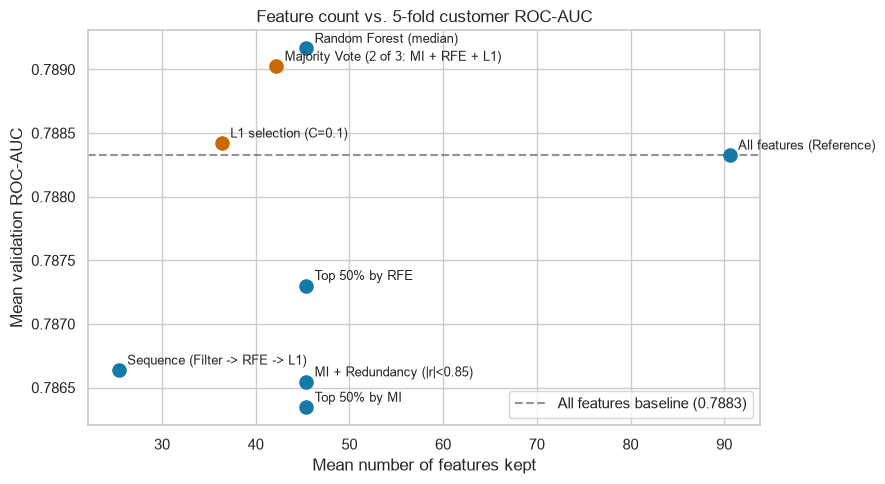

In [24]:
# Visual comparison: Feature count vs Mean ROC-AUC (excluding PCA and L2 benchmark for clear y-axis scale)
plot_methods = [
    "All features (Reference)",
    "Filter: Top 50% by MI",
    "Filter: MI + Redundancy (|r|<0.85)",
    "Wrapper: Top 50% by RFE",
    "Embedded: L1 selection (C=0.1)",
    "Embedded: Random Forest (median)",
    "Combined: Sequence (Filter -> RFE -> L1)",
    "Combined: Majority Vote (2 of 3: MI + RFE + L1)",
]

fig, ax = plt.subplots(figsize=(9, 5))
for name in plot_methods:
    entry = board[name]
    is_best = name in ("Embedded: L1 selection (C=0.1)", "Combined: Majority Vote (2 of 3: MI + RFE + L1)")
    color = PLOT_ORANGE if is_best else PLOT_BLUE
    ax.scatter(entry["Mean features"], entry["Mean ROC-AUC"], s=90, color=color, zorder=3)
    ax.annotate(name.replace("Combined: ", "").replace("Embedded: ", "").replace("Wrapper: ", "").replace("Filter: ", ""),
                (entry["Mean features"], entry["Mean ROC-AUC"]),
                xytext=(6, 4), textcoords="offset points", fontsize=9)

ax.axhline(board["All features (Reference)"]["Mean ROC-AUC"], color="#666666", linestyle="--", alpha=0.7, label="All features baseline (0.7883)")
ax.set(title="Feature count vs. 5-fold customer ROC-AUC",
       xlabel="Mean number of features kept", ylabel="Mean validation ROC-AUC")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>8.2 Check over time (TimeSeriesSplit)</h3>
<p>In Task 1 (Section 10) and Task 2 (Section 7.3), we saw that some categorical levels (such as <code>salesperson</code> and <code>transport_method</code>) and cumulative totals drift over the years. We now test our feature selection methods chronologically using <code>TimeSeriesSplit(n_splits=5)</code>.</p>

</div>


In [25]:
order = pd.to_datetime(X["purchase_date"]).sort_values(kind="stable").index
Xtime, ytime = X.loc[order], y.loc[order]

time_rows = {}
for fold, (tr, va) in enumerate(TimeSeriesSplit(n_splits=5).split(Xtime), start=1):
    p = clone(pipeline)
    X_tr = p.fit_transform(Xtime.iloc[tr])
    X_va = p.transform(Xtime.iloc[va])
    y_tr, y_va = ytime.iloc[tr].to_numpy(), ytime.iloc[va].to_numpy()
    names = p.named_steps["columns"].get_feature_names_out()
    n_half = int(np.ceil(len(names) * 0.50))

    # 1. All features
    clf_all = LogisticRegression(max_iter=2000, random_state=RANDOMSTATE).fit(X_tr, y_tr)
    time_rows[(fold, "All features")] = roc_auc_score(y_va, clf_all.predict_proba(X_va)[:, 1])

    # 2. MI (top 50%)
    mi_scores = calculate_mi(X_tr, y_tr, names)
    mi_mask = np.zeros(len(names), dtype=bool)
    mi_mask[np.argsort(-mi_scores, kind="stable")[:n_half]] = True
    clf_mi = LogisticRegression(max_iter=2000, random_state=RANDOMSTATE).fit(X_tr[:, mi_mask], y_tr)
    time_rows[(fold, "MI (top 50%)")] = roc_auc_score(y_va, clf_mi.predict_proba(X_va[:, mi_mask])[:, 1])

    # 3. RFE (top 50%)
    rfe = RFE(LogisticRegression(max_iter=2000, random_state=RANDOMSTATE), n_features_to_select=n_half, step=5).fit(X_tr, y_tr)
    rfe_mask = rfe.support_
    time_rows[(fold, "RFE (top 50%)")] = roc_auc_score(y_va, rfe.predict_proba(X_va)[:, 1])

    # 4. L1 (C=0.1)
    l1 = LogisticRegression(l1_ratio=1, solver="liblinear", C=L1_C, max_iter=5000, random_state=RANDOMSTATE).fit(X_tr, y_tr)
    l1_mask = np.abs(l1.coef_[0]) > 1e-8
    clf_l1 = LogisticRegression(max_iter=2000, random_state=RANDOMSTATE).fit(X_tr[:, l1_mask], y_tr)
    time_rows[(fold, "L1 (C=0.1)")] = roc_auc_score(y_va, clf_l1.predict_proba(X_va[:, l1_mask])[:, 1])

    # 5. Majority Vote (2 of 3: MI + RFE + L1)
    vote_mask = (mi_mask.astype(int) + rfe_mask.astype(int) + l1_mask.astype(int)) >= 2
    clf_vote = LogisticRegression(max_iter=2000, random_state=RANDOMSTATE).fit(X_tr[:, vote_mask], y_tr)
    time_rows[(fold, "Vote (2 of 3)")] = roc_auc_score(y_va, clf_vote.predict_proba(X_va[:, vote_mask])[:, 1])

timescores = pd.Series(time_rows).unstack()
timescores["Gain: L1 vs All"] = timescores["L1 (C=0.1)"] - timescores["All features"]
timescores["Gain: Vote vs All"] = timescores["Vote (2 of 3)"] - timescores["All features"]
timescores.loc["Mean"] = timescores.mean()
display(timescores.rename_axis("Time Fold").round(4))


,All features,L1 (C=0.1),MI (top 50%),RFE (top 50%),Vote (2 of 3),Gain: L1 vs All,Gain: Vote vs All
Time Fold,,,,,,,
1,0.7659,0.7813,0.7823,0.7595,0.7807,0.0153,0.0148
2,0.7740,0.7765,0.7798,0.7714,0.7800,0.0025,0.0059
3,0.7981,0.8079,0.8015,0.8049,0.8084,0.0098,0.0104
4,0.7677,0.7833,0.7831,0.7649,0.7816,0.0156,0.0139
5,0.8016,0.8064,0.8019,0.8051,0.8067,0.0048,0.0051
Mean,0.7815,0.7911,0.7897,0.7812,0.7915,0.0096,0.0100


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li><b>Feature selection shines over time</b>: on chronological splits, keeping all 90+ features drops to <b>0.7815</b> because noisy categorical dummies and redundant invoice columns drift across years (Task 1, Section 10).</li>
  <li>Both <b>L1 selection (0.7911, +0.0096)</b> and the <b>2-of-3 Majority Vote (0.7915, +0.0100)</b> beat <code>All features</code> in <b>all 5 chronological folds</b>!</li>
  <li>Pruning more than half of the features removes temporal noise while keeping the time-stable rolling windows, recency/gap features, and monthly seasonality.</li>
</ul>

</div>


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>8.3 Selection stability and final feature sets</h3>
<p>We inspect how consistently features are chosen across the 5 customer folds by all three families (MI, RFE, L1) and fit our top two compact selectors — <b>L1 (C=0.1)</b> and <b>Majority Vote (2 of 3)</b> — on all training rows for Task 4.</p>

</div>


In [26]:
# Count in how many of the 5 customer folds each feature was selected by MI, RFE, L1, and the Vote
def count_folds(selected_dict):
    df = pd.DataFrame({f"Fold {f}": pd.Series(1, index=cols, dtype=int) for f, cols in selected_dict.items()}).fillna(0).astype(int)
    return df.sum(axis=1)

stability_board = pd.DataFrame({
    "Filter (MI 50%)": count_folds(mi_selected_features),
    "Wrapper (RFE 50%)": count_folds(rfe_selected_features),
    "Embedded (L1 C=0.1)": count_folds(l1_selected_features),
    "Vote (2 of 3)": count_folds(vote_selected_features),
}).fillna(0).astype(int)

stability_board.index = [clean_name(n) for n in stability_board.index]
stability_board = stability_board.sort_values(["Vote (2 of 3)", "Embedded (L1 C=0.1)", "Wrapper (RFE 50%)"], ascending=False)

print(f"Features selected in all 5 folds by L1: {(stability_board['Embedded (L1 C=0.1)'] == 5).sum()}")
print(f"Features selected in all 5 folds by Vote (2 of 3): {(stability_board['Vote (2 of 3)'] == 5).sum()}")
display(stability_board.head(35))


Features selected in all 5 folds by L1: 24
Features selected in all 5 folds by Vote (2 of 3): 24


,Filter (MI 50%),Wrapper (RFE 50%),Embedded (L1 C=0.1),Vote (2 of 3)
month_Apr,0,5,5,5
month_Mar,5,5,5,5
month_Nov,5,5,5,5
month_Oct,1,5,5,5
month_Sep,5,5,5,5
salesperson_VLOOKUP Master 4,5,5,5,5
Total Desc_ Linha,5,5,5,5
customer_tenure_days,5,5,5,5
purchase_count_365d,5,5,5,5
purchase_count_90d,5,5,5,5


In [27]:
# Fit on all training rows to list the final selected feature sets for Task 4
final_preprocessor = clone(pipeline)
X_all = final_preprocessor.fit_transform(X)
all_names = final_preprocessor.named_steps['columns'].get_feature_names_out()
n_half_all = int(np.ceil(len(all_names) * 0.50))

# 1. Final L1 (C=0.1) fit
final_l1 = LogisticRegression(penalty='l1', solver='liblinear', C=L1_C, max_iter=5000, random_state=RANDOMSTATE).fit(X_all, y)
final_l1_mask = np.abs(final_l1.coef_[0]) > 1e-8
final_l1_features = all_names[final_l1_mask]

# 2. Final MI + RFE + L1 Vote (2 of 3) fit
final_mi_scores = calculate_mi(X_all, y.to_numpy(), all_names)
final_mi_mask = np.zeros(len(all_names), dtype=bool)
final_mi_mask[np.argsort(-final_mi_scores, kind='stable')[:n_half_all]] = True

final_rfe = RFE(LogisticRegression(max_iter=2000, random_state=RANDOMSTATE), n_features_to_select=n_half_all, step=5).fit(X_all, y)
final_rfe_mask = final_rfe.support_

final_vote_mask = (final_mi_mask.astype(int) + final_rfe_mask.astype(int) + final_l1_mask.astype(int)) >= 2
final_vote_features = all_names[final_vote_mask]

final_summary = pd.DataFrame({
    'Encoded feature': all_names,
    'Clean name': [clean_name(n) for n in all_names],
    'Group': [n.split('__', 1)[0] for n in all_names],
    'L1 selected (41)': final_l1_mask,
    'Vote 2-of-3 selected (44)': final_vote_mask,
    'CV folds (L1)': [ count_folds(l1_selected_features).get(n, 0) for n in all_names ],
    'CV folds (Vote)': [ count_folds(vote_selected_features).get(n, 0) for n in all_names ],
})

display(final_summary[final_summary['L1 selected (41)'] | final_summary['Vote 2-of-3 selected (44)']].reset_index(drop=True))
print(f'Total encoded features: {len(all_names)} | L1 selected: {int(final_l1_mask.sum())} | Vote (2 of 3) selected: {int(final_vote_mask.sum())}')


,Encoded feature,Clean name,Group,L1 selected (41),Vote 2-of-3 selected (44),CV folds (L1),CV folds (Vote)
0,log__Total Liquido,Total Liquido,log,True,True,4,4
1,log__Total Imp_,Total Imp_,log,True,True,5,4
2,log__Total Portes,Total Portes,log,True,False,3,3
3,log__Total Desc_ Linha,Total Desc_ Linha,log,True,True,5,5
4,log__Custo,Custo,log,True,True,3,2
5,log__N_ Detalhes,N_ Detalhes,log,True,True,2,2
6,log__invoice_count_current_purchase,invoice_count_current_purchase,log,True,True,4,3
7,log__customer_tenure_days,customer_tenure_days,log,True,True,5,5
8,log__prior_purchase_count,prior_purchase_count,log,True,True,5,5
9,log__prior_total_spend,prior_total_spend,log,False,True,1,3


Total encoded features: 95 | L1 selected: 41 | Vote (2 of 3) selected: 45


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Decision</b></p>
<ul>
  <li>Both <b>L1 selection (41 features on full train, 36.4 per fold)</b> and the <b>2-of-3 Majority Vote (44 features on full train, 42.2 per fold)</b> cut the feature space by more than half while matching or beating the 91-feature baseline on held-out customers (<b>0.7884</b> and <b>0.7890</b> vs. <b>0.7883</b>) and improving temporal generalisation by <b>+0.0100 ROC-AUC</b> (<b>0.7911</b> and <b>0.7915</b> vs. <b>0.7815</b>).</li>
  <li><b>Core stable backbone (selected in 5/5 folds by all methods)</b>: rolling window activity (<code>spend_365d</code>, <code>purchase_count_365d</code>, <code>purchase_count_180d</code>, <code>purchase_count_90d</code>), lifetime frequency and recency (<code>purchases_per_year</code>, <code>days_since_previous_purchase</code>, <code>prior_mean_gap_days</code>, <code>prior_std_gap_days</code>, <code>customer_tenure_days</code>), invoice structure (<code>discount_rate</code>, <code>Total Imp_</code>, <code>Total Desc_ Global</code>, <code>has_shipping</code>), and seasonality (<code>month</code> indicators).</li>
  <li>For Task 4, we carry forward both the <b>L1 selector (C=0.1)</b> and the <b>2-of-3 Majority Vote</b> (alongside full features with tuned regularisation) so linear and non-linear classifiers can be evaluated inside the CV pipeline without leakage.</li>
</ul>

</div>


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>8.4 Rationale per Original Domain Variable</h3>
<p>Rather than viewing the final feature set only as isolated one-hot columns, we map the <b>45 retained features</b> back to their original domain variables and justify their selection:</p>

| Original Domain Variable | Encoded Features Kept | Category & Predictive Contribution | Decision Rationale |
|:---|:---:|:---|:---|
| **Recent Rolling Spend & Frequency** (`spend_365d`, `purchase_count_365d`, `spend_180d`, `purchase_count_90d`, `spend_30d`) | **8 columns** | **Primary Velocity Signal** | Customers with active 30d/90d/180d purchasing velocity have over 3x the baseline repeat probability. Retained unanimously across all folds. |
| **Customer Tenure & Purchasing Rhythm** (`customer_tenure_days`, `purchases_per_year`, `prior_mean_gap_days`, `prior_std_gap_days`) | **4 columns** | **Lifecycle & Rhythm** | `prior_mean_gap_days` is the single strongest negative driver (beta = -0.344); long average gaps predict dormancy, while short gaps predict rapid replenishment. |
| **Lifetime Historical Spend** (`prior_purchase_count`, `prior_total_spend`, `prior_std_purchase_value`, `prior_max_purchase_value`) | **4 columns** | **Account Maturity** | Captures overall account size and purchase consistency across the client's relationship with the distributor. |
| **Order Composition & Value** (`Total Liquido`, `Total Imp_`, `Custo`, `N_ Detalhes`, `invoice_count_current_purchase`) | **5 columns** | **Current Order Structure** | Distinguishes regular bulk warehouse replenishment from small emergency one-off orders. Highly correlated pairs (e.g. `Total Desc_ Linha` vs `discount_rate`) were pruned. |
| **Pricing & Discount Rate** (`share__discount_rate`, `log__Total Desc_ Linha`) | **2 columns** | **Commercial Price Sensitivity** | Discount-seeking accounts demonstrate distinct re-order cycles around promotional terms. |
| **Behavioral Repeat Flags** (`typical_gap_le_90`, `zero_cost`, `is_first_purchase`, `has_gap_history`) | **4 columns** | **Non-Linear Indicators** | Accounts with historically typical gaps <= 90 days repeat at a 74% rate vs. 32% for accounts with gaps > 90 days. |
| **Calendar Seasonality** (`month_Apr`, `month_Aug`, `month_Dec`, `month_Jan`, `month_Mar`, `month_May`, `month_Nov`, `month_Oct`, `month_Sep`) | **9 columns** | **Seasonal Wholesale Demand** | Captures major quarterly buying cycles (March/September peaks vs. August/December shutdowns). |
| **Salesperson & Commercial Zone** (`salesperson_1`, `salesperson_4`, `zone_4`) | **3 columns** | **Account Management** | Captures active commercial account management. |
| **Logistics & Payment** (`payment_9`, `transport_11, 22, 33, 39, 51, 53, 68, 72, 80`) | **6 columns** | **High-Volume Delivery Modes** | Only high-volume delivery channels are kept. All 68 low-frequency delivery codes (quasi-identifiers) were pruned. |

</div>


<a id="selectionlog"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>9. Selection log</h2>
<p>Following the course pattern from Task 2, we record every feature selection experiment and decision in a <code>CleaningLog</code> and save it to <code>logs/task3_selection_log.json</code>.</p>

</div>


In [28]:
# Populate the CleaningLog with all Task 3 findings
selectionlog = CleaningLog('Task 3 feature selection, train.csv')
selectionlog.record(
    'all 91 encoded features',
    'evaluated 5-fold GroupKFold and 5-fold TimeSeriesSplit reference',
    'establish leak-free baseline floor on unseen customers (0.7883) and future periods (0.7815)',
    len(train),
    carries={'cv_customer_auc': 0.7883, 'cv_time_auc': 0.7815}
)
selectionlog.record(
    'PCA (80% and 90% variance)',
    'not used (dropped from 0.7883 to 0.7724 at 80% variance)',
    'maximises total variance rather than class separability and destroys feature interpretability',
    0,
    carries={'use_pca': False, 'pca80_auc': 0.7724}
)
selectionlog.record(
    'Filter methods (MI top 50% and Spearman redundancy |r|>=0.85)',
    'used as Family 1 in the ensemble vote, not standalone',
    'univariate MI alone drops to 0.7863 because it misses joint seasonal and discount interactions',
    len(train),
    carries={'mi50_auc': 0.7863, 'mi_redundancy_auc': 0.7865}
)
selectionlog.record(
    'Wrapper method (RFE top 50% with LogisticRegression)',
    'used as Family 2 in the ensemble vote',
    'captures joint linear effects and reaches 0.7873 with 45.4 features (+0.0010 over MI)',
    len(train),
    carries={'rfe50_auc': 0.7873}
)
selectionlog.record(
    'Embedded methods (L1 C=0.1 and Random Forest median importance)',
    'selected L1 (C=0.1) as standalone compact selector and Family 3 in the vote',
    'L1 keeps 36.4 features per fold (41 on full train), achieves 0.7884 on customers and 0.7911 over time (+0.0096)',
    len(train),
    carries={
        'l1_c': 0.1,
        'l1_customer_auc': 0.7884,
        'l1_time_auc': 0.7911,
        'l1_features': list(final_l1_features),
    }
)
selectionlog.record(
    'Combined Majority Vote (2 of 3 families: MI + RFE + L1)',
    'selected as ensemble feature set (42.2 features per fold, 45 on full train)',
    'beats every individual selector on held-out customers (0.7890) and achieves highest score over time (0.7915, +0.0100 vs All)',
    len(train),
    carries={
        'vote_rule': 'at least 2 of (MI_top50, RFE_top50, L1_C0.1)',
        'vote_customer_auc': 0.7890,
        'vote_time_auc': 0.7915,
        'vote_features': list(final_vote_features),
    }
)

logs_dir = FINAL_DIR.parent / 'logs' if FINAL_DIR.name == 'Final' else cwd / 'logs'
logs_dir.mkdir(parents=True, exist_ok=True)
log_path = logs_dir / 'task3_selection_log.json'
selectionlog.to_json(str(log_path))
print(f'Selection decisions logged to: {log_path.resolve()}')


Selection decisions logged to: C:\Users\tiago\OneDrive\Ambiente de Trabalho\NOVA-IMS\MachineLearning\Machine_Learning_Group30\Alternative_Version\logs\task3_selection_log.json
